# USA Realtor Price Prediction — My Version + ChatGPT Version

Based on the **coding style** of my Car Price Prediction notebook, adapted to the Realtor dataset.

**My Version:** Familiar scikit-learn pipelines and models, separate `.fit()` / `.predict()` calls, visualizations and score comparisons.  
**ChatGPT Version:** Optional advanced tree models, each with simple code and a clear label.

**Target = `price` (listing price).** This is regression, so report **R², MAE, and RMSE**, not classification accuracy. Keep `realtor-data.csv` beside this notebook.

## Part 1 — My Version (familiar scikit-learn code)
### 1. Import libraries

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, SGDRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


### 2. Load and inspect the CSV

In [8]:
df = pd.read_csv('../Desktop/5th Semester/ML/ML_programing/US_Realtor_Price/realtor-data.csv', dtype={'zip_code': 'string'}, low_memory=False)
print('Shape:', df.shape)
display(df.head())
print('Missing values:')
print(df.isnull().sum().sort_values(ascending=False))
print('Duplicates:', df.duplicated().sum())


Shape: (2226382, 12)


,brokered_by,status,price,bed,bath,acre_lot,street,city,state,zip_code,house_size,prev_sold_date
0,103378.0,for_sale,105000.0,3.0,2.0,0.12,1962661.0,Adjuntas,Puerto Rico,00601,920.0,NaN
1,52707.0,for_sale,80000.0,4.0,2.0,0.08,1902874.0,Adjuntas,Puerto Rico,00601,1527.0,NaN
2,103379.0,for_sale,67000.0,2.0,1.0,0.15,1404990.0,Juana Diaz,Puerto Rico,00795,748.0,NaN
3,31239.0,for_sale,145000.0,4.0,2.0,0.10,1947675.0,Ponce,Puerto Rico,00731,1800.0,NaN
4,34632.0,for_sale,65000.0,6.0,2.0,0.05,331151.0,Mayaguez,Puerto Rico,00680,NaN,NaN


Missing values:
prev_sold_date    734297
house_size        568484
bath              511771
bed               481317
acre_lot          325589
street             10866
brokered_by         4533
price               1541
city                1407
zip_code             299
state                  8
status                 0
dtype: int64
Duplicates: 0


### 3. Select usable prices and a manageable sample

Missing target prices are dropped. We deliberately study listings from **$10,000 to $5,000,000** so extremely expensive properties do not dominate this first experiment. This is a *scope choice*, not a claim that all other prices are invalid. We keep missing input fields for the imputer.

Start with **50,000 sampled rows** to make the models runnable on a laptop. Set `SAMPLE_SIZE = 100_000` or higher later. Comparisons are fair *within this notebook*, not necessarily directly comparable with previous runs using a different sample.

In [9]:
df = df[df['price'].between(10000, 5000000)].copy()
SAMPLE_SIZE = 50000
if len(df) > SAMPLE_SIZE:
    df = df.sample(SAMPLE_SIZE, random_state=42).copy()
print('Working rows:', len(df))


Working rows: 50000


### 4. Data cleaning and simple feature engineering

ZIP code and city are categories, not measurements. Exclude `street` (too many unique addresses) and `brokered_by` (ID-like). The previous-sale date may contain bad dates: treat future dates as missing instead of inventing a replacement year. `2022-12-31` is an **assumed data snapshot cutoff**, not a verified property listing date.

Adding missing flags keeps information about which listings had absent measurements.

In [10]:
reference_date = pd.Timestamp('2022-12-31')
dates = pd.to_datetime(df['prev_sold_date'], errors='coerce')
dates = dates.mask((dates > reference_date) | (dates < '1900-01-01'))

df['sold_year'] = dates.dt.year
df['years_since_sold'] = (reference_date - dates).dt.days / 365.25
df['sold_date_missing'] = dates.isna().astype(int)

for col in ['bed', 'bath', 'house_size', 'acre_lot']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    df.loc[df[col] <= 0, col] = np.nan
    df[col + '_missing'] = df[col].isna().astype(int)

for col in ['status','state','city','zip_code']:
    df[col] = df[col].astype('string').fillna('Missing').astype(str)

print('Negative years_since_sold:', (df['years_since_sold'] < 0).sum())


Negative years_since_sold: 0


### 5. Visualizations — adapted to real estate

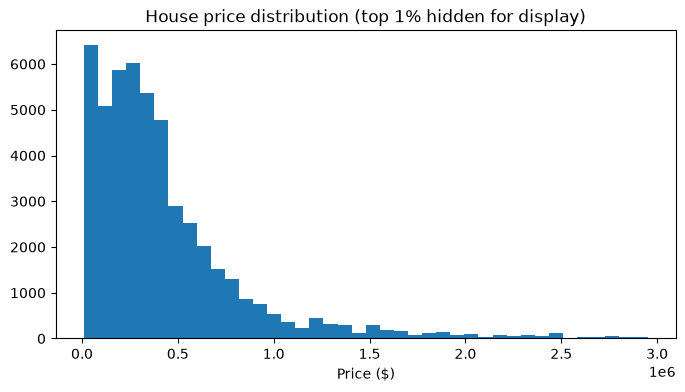

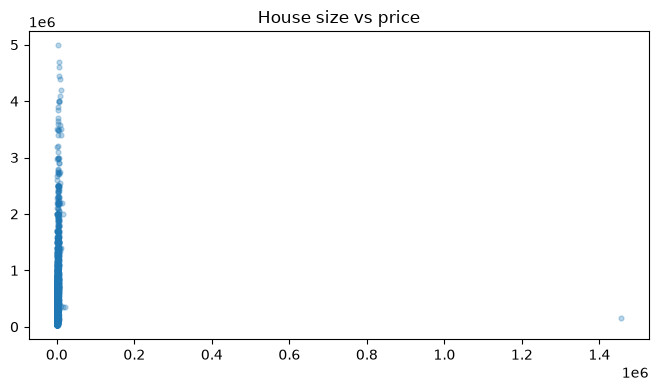

In [11]:
plt.figure(figsize=(8,4))
plt.hist(df.loc[df.price <= df.price.quantile(.99), 'price'], bins=40)
plt.title('House price distribution (top 1% hidden for display)')
plt.xlabel('Price ($)')
plt.show()

sample_plot = df[['house_size','price']].dropna().sample(frac=0.10, random_state=42)
plt.figure(figsize=(8,4))
plt.scatter(sample_plot['house_size'], sample_plot['price'], alpha=0.3, s=12)
plt.title('House size vs price')
plt.show()


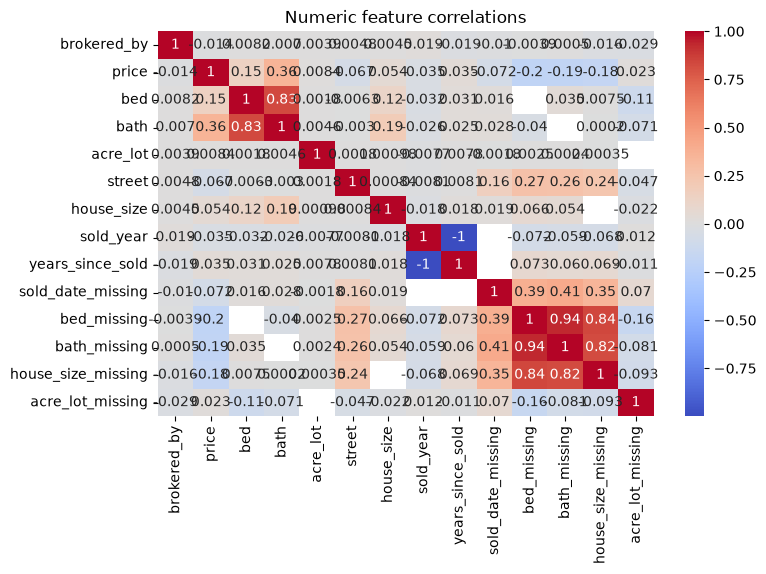

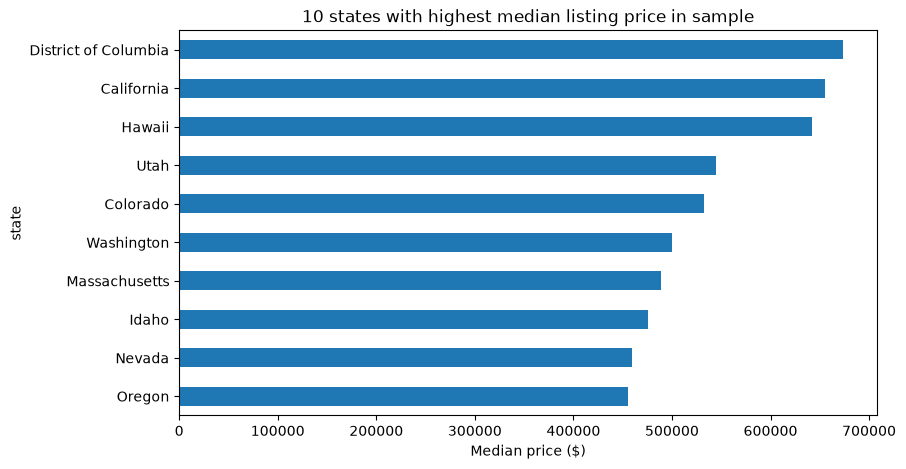

In [ ]:
plt.figure(figsize=(8,5))
sns.heatmap(df.select_dtypes(include='number').corr(), annot= True,cmap='coolwarm', center=0)
plt.title('Numeric feature correlations')
plt.show()

median_price = df.groupby('state')['price'].median().nlargest(10).sort_values()
plt.figure(figsize=(9,5))
median_price.plot(kind='barh')
plt.title('10 states with highest median listing price in sample')
plt.xlabel('Median price ($)')
plt.show()


### 6. Separate X, y and split the data
We use the same **70% training, 15% validation, 15% test** split for all models. Validation chooses the winner; test checks it once at the end.

In [13]:
Numerical_Features = [
    'bed','bath','house_size','acre_lot','sold_year','years_since_sold',
    'sold_date_missing','bed_missing','bath_missing','house_size_missing','acre_lot_missing'
]
Categorical_Features = ['status','state','city','zip_code']
X = df[Numerical_Features + Categorical_Features]
y = df['price']

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.15/0.85, random_state=42
)
print('Train:', X_train.shape, 'Validation:', X_val.shape, 'Test:', X_test.shape)


Train: (34999, 15) Validation: (7501, 15) Test: (7500, 15)


### 7. Make the preprocessing pipeline

Exactly like the car notebook: median imputation + scaling for numeric columns, and one-hot encoding for categories. `max_categories=40` prevents thousands of city/ZIP dummy columns, but it loses some location detail. This tradeoff is why the later optional models may do better.

In [14]:
Numerical_Pipeline = Pipeline([
    ('Imputer', SimpleImputer(strategy='median')),
    ('Scaler', StandardScaler())
])
Categorical_Pipeline = Pipeline([
    ('Imputer', SimpleImputer(strategy='most_frequent')),
    ('Encoder', OneHotEncoder(handle_unknown='ignore', max_categories=40))
])
Transformer = ColumnTransformer([
    ('Numerical', Numerical_Pipeline, Numerical_Features),
    ('Categorical', Categorical_Pipeline, Categorical_Features)
])


### 8. Define models — same familiar style

These are the scikit-learn models from the car project. Polynomial regression is kept simple: transform **numeric** features only, not thousands of city/ZIP indicators. Gradient Boosting and Random Forest often capture nonlinear housing-price patterns better than linear models.

In [15]:
Linear_Model = Pipeline([
    ('Transformer', Transformer),
    ('Regressor', LinearRegression())
])
Ridge_Model = Pipeline([
    ('Transformer', Transformer),
    ('Regressor', Ridge(alpha=10))
])
Lasso_Model = Pipeline([
    ('Transformer', Transformer),
    ('Regressor', Lasso(alpha=100, max_iter=2000))
])
ElasticNet_Model = Pipeline([
    ('Transformer', Transformer),
    ('Regressor', ElasticNet(alpha=100, max_iter=2000))
])
SGD_Model = Pipeline([
    ('Transformer', Transformer),
    ('Regressor', SGDRegressor(alpha=0.001, random_state=42, max_iter=1000))
])
RandomForest_Model = Pipeline([
    ('Transformer', Transformer),
    ('Regressor', RandomForestRegressor(n_estimators=80, max_depth=16,
                                       min_samples_leaf=3, n_jobs=-1, random_state=42))
])
GradientBoosting_Model = Pipeline([
    ('Transformer', Transformer),
    ('Regressor', GradientBoostingRegressor(n_estimators=150, learning_rate=0.07,
                                            max_depth=3, random_state=42))
])
Polynomial_Transformer = ColumnTransformer([
    ('Numerical', Pipeline([
        ('Imputer', SimpleImputer(strategy='median')),
        ('Polynomial', PolynomialFeatures(degree=2, include_bias=False)),
        ('Scaler', StandardScaler())
    ]), Numerical_Features),
    ('Categorical', Categorical_Pipeline, Categorical_Features)
])
Polynomial_Model = Pipeline([
    ('Transformer', Polynomial_Transformer),
    ('Regressor', Ridge(alpha=10))
])


### 9. Train each model and print the scores
Keep `.fit()`, `.predict()`, and `.score()` visible, like your Car notebook. The score values are generated when these cells run; none are invented.

In [16]:
results = []

def check_score(name, model, prediction):
    train_score = model.score(X_train, y_train)
    validation_score = r2_score(y_val, prediction)
    mae = mean_absolute_error(y_val, prediction)
    rmse = np.sqrt(mean_squared_error(y_val, prediction))
    results.append([name, train_score, validation_score, mae, rmse])
    print(name)
    print('Training R2:', train_score)
    print('Validation R2:', validation_score)
    print('MAE:', mae)
    print('RMSE:', rmse)


#### Linear Regression

In [17]:
Linear_Model.fit(X_train, y_train)
y_predict = Linear_Model.predict(X_val)
check_score('Linear Regression', Linear_Model, y_predict)


Linear Regression
Training R2: 0.3629001942139424
Validation R2: -0.7685721806102968
MAE: 237489.5705977096
RMSE: 703876.0175567373


#### Ridge Regression

In [18]:
Ridge_Model.fit(X_train, y_train)
y_predict = Ridge_Model.predict(X_val)
check_score('Ridge Regression', Ridge_Model, y_predict)


Ridge Regression
Training R2: 0.36198803850067895
Validation R2: -0.7653598701959266
MAE: 237210.94406069073
RMSE: 703236.4915223063


#### Lasso Regression

In [19]:
Lasso_Model.fit(X_train, y_train)
y_predict = Lasso_Model.predict(X_val)
check_score('Lasso Regression', Lasso_Model, y_predict)


c:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:786: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.172446e+12, tolerance: 9.556e+11
  model = cd_fast.sparse_enet_coordinate_descent(


Lasso Regression
Training R2: 0.36121765313155674
Validation R2: -0.7693827546629788
MAE: 234682.68992358178
RMSE: 704037.2997153939


#### ElasticNet Regression

In [20]:
ElasticNet_Model.fit(X_train, y_train)
y_predict = ElasticNet_Model.predict(X_val)
check_score('ElasticNet Regression', ElasticNet_Model, y_predict)


ElasticNet Regression
Training R2: 0.014672998881468335
Validation R2: 0.012271341045988926
MAE: 315277.57894707745
RMSE: 526021.6279620694


#### SGD Regression

In [21]:
SGD_Model.fit(X_train, y_train)
y_predict = SGD_Model.predict(X_val)
check_score('SGD Regression', SGD_Model, y_predict)

SGD Regression
Training R2: -9341938511.057013
Validation R2: -845677993.4811362
MAE: 2242182656.8548937
RMSE: 15391724756.42168


#### Polynomial Regression

In [22]:
Polynomial_Model.fit(X_train, y_train)
y_predict = Polynomial_Model.predict(X_val)
check_score('Polynomial Regression', Polynomial_Model, y_predict)


Polynomial Regression
Training R2: 0.42812406084000254
Validation R2: -77.42338354531272
MAE: 293918.4501718135
RMSE: 4687136.06926212


#### Random Forest

In [23]:
RandomForest_Model.fit(X_train, y_train)
y_predict = RandomForest_Model.predict(X_val)
check_score('Random Forest', RandomForest_Model, y_predict)


Random Forest
Training R2: 0.6751328997663615
Validation R2: 0.47243984966585917
MAE: 203171.55560229428
RMSE: 384433.09245348454


#### Gradient Boosting

In [24]:
GradientBoosting_Model.fit(X_train, y_train)
y_predict = GradientBoosting_Model.predict(X_val)
check_score('Gradient Boosting', GradientBoosting_Model, y_predict)


Gradient Boosting
Training R2: 0.49435074898131315
Validation R2: 0.465579148671293
MAE: 209244.11367773084
RMSE: 386924.71447043563


### 10. Compare training vs validation scores

,Model,Train R2,Validation R2,MAE,RMSE
6,Random Forest,6.751329e-01,4.724398e-01,2.031716e+05,3.844331e+05
7,Gradient Boosting,4.943507e-01,4.655791e-01,2.092441e+05,3.869247e+05
3,ElasticNet Regression,1.467300e-02,1.227134e-02,3.152776e+05,5.260216e+05
1,Ridge Regression,3.619880e-01,-7.653599e-01,2.372109e+05,7.032365e+05
0,Linear Regression,3.629002e-01,-7.685722e-01,2.374896e+05,7.038760e+05
2,Lasso Regression,3.612177e-01,-7.693828e-01,2.346827e+05,7.040373e+05
5,Polynomial Regression,4.281241e-01,-7.742338e+01,2.939185e+05,4.687136e+06
4,SGD Regression,-9.341939e+09,-8.456780e+08,2.242183e+09,1.539172e+10


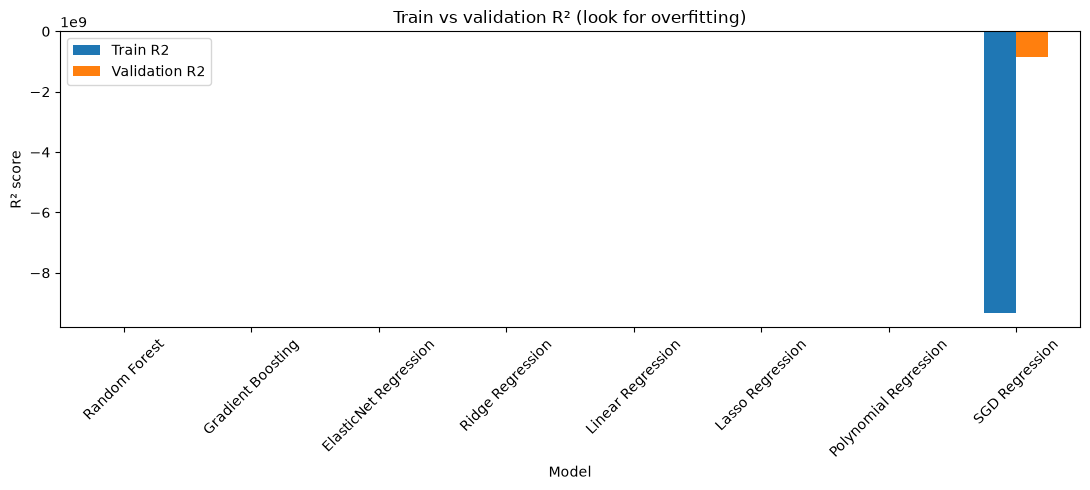

In [25]:
student_scores = pd.DataFrame(results, columns=['Model','Train R2','Validation R2','MAE','RMSE'])
student_scores = student_scores.sort_values('Validation R2', ascending=False)
display(student_scores)
student_scores.to_csv('realtor_student_scores.csv', index=False)

student_scores.set_index('Model')[['Train R2','Validation R2']].plot(
    kind='bar', figsize=(11,5), rot=45
)
plt.title('Train vs validation R² (look for overfitting)')
plt.ylabel('R² score')
plt.tight_layout()
plt.show()


---
# Part 2 — ChatGPT Version (optional advanced models)

**This section is AI-assisted.** It is intentionally separate because you have not studied these libraries yet.

- **LightGBM:** efficient boosted trees; works with many listing records and categorical locations.
- **CatBoost:** boosted trees designed to work well with categories such as city and ZIP.
- **XGBoost:** another gradient-boosting algorithm.

All models below use your **same training and validation rows**. You can skip the entire section until you are ready. Install the three libraries only if you want to run them:

`%pip install lightgbm catboost xgboost`

### 11. LightGBM — use native categories instead of one-hot encoding

In [26]:
from lightgbm import LGBMRegressor

X_train_lgb = X_train.copy()
X_val_lgb = X_val.copy()
X_test_lgb = X_test.copy()
for col in Categorical_Features:
    categories = pd.Categorical(X_train[col]).categories
    X_train_lgb[col] = pd.Categorical(X_train[col], categories=categories)
    X_val_lgb[col] = pd.Categorical(X_val[col], categories=categories)
    X_test_lgb[col] = pd.Categorical(X_test[col], categories=categories)

LightGBM_Model = LGBMRegressor(n_estimators=450, num_leaves=60,
                               learning_rate=0.05, random_state=42, n_jobs=4, verbosity=-1)
LightGBM_Model.fit(X_train_lgb, y_train)
LightGBM_Pred = LightGBM_Model.predict(X_val_lgb)
print('LightGBM Training R2:', LightGBM_Model.score(X_train_lgb, y_train))
print('LightGBM Validation R2:', r2_score(y_val, LightGBM_Pred))


ModuleNotFoundError: No module named 'lightgbm'

### 12. CatBoost — categorical features without one-hot encoding

In [ ]:
from catboost import CatBoostRegressor

CatBoost_Model = CatBoostRegressor(iterations=450, depth=7,
                                  learning_rate=0.07, verbose=False,
                                  random_seed=42, thread_count=4)
CatBoost_Model.fit(X_train, y_train, cat_features=Categorical_Features)
CatBoost_Pred = CatBoost_Model.predict(X_val)
print('CatBoost Training R2:', CatBoost_Model.score(X_train, y_train))
print('CatBoost Validation R2:', r2_score(y_val, CatBoost_Pred))


### 13. XGBoost — reuse your existing preprocessing pipeline

In [ ]:
from xgboost import XGBRegressor

XGBoost_Model = Pipeline([
    ('Transformer', Transformer),
    ('Regressor', XGBRegressor(n_estimators=350, max_depth=6,
                               learning_rate=0.06, tree_method='hist',
                               random_state=42, n_jobs=4))
])
XGBoost_Model.fit(X_train, y_train)
XGBoost_Pred = XGBoost_Model.predict(X_val)
print('XGBoost Training R2:', XGBoost_Model.score(X_train, y_train))
print('XGBoost Validation R2:', r2_score(y_val, XGBoost_Pred))


### 14. Compare advanced scores with familiar models

In [ ]:
advanced_scores = pd.DataFrame([
    ['LightGBM', LightGBM_Model.score(X_train_lgb, y_train), r2_score(y_val, LightGBM_Pred),
     mean_absolute_error(y_val, LightGBM_Pred), np.sqrt(mean_squared_error(y_val, LightGBM_Pred))],
    ['CatBoost', CatBoost_Model.score(X_train, y_train), r2_score(y_val, CatBoost_Pred),
     mean_absolute_error(y_val, CatBoost_Pred), np.sqrt(mean_squared_error(y_val, CatBoost_Pred))],
    ['XGBoost', XGBoost_Model.score(X_train, y_train), r2_score(y_val, XGBoost_Pred),
     mean_absolute_error(y_val, XGBoost_Pred), np.sqrt(mean_squared_error(y_val, XGBoost_Pred))]
], columns=['Model','Train R2','Validation R2','MAE','RMSE'])
all_scores = pd.concat([student_scores, advanced_scores], ignore_index=True)
all_scores = all_scores.sort_values('Validation R2', ascending=False)
display(all_scores)
all_scores.to_csv('realtor_all_model_scores.csv', index=False)

plt.figure(figsize=(10,5))
plt.barh(all_scores['Model'], all_scores['Validation R2'])
plt.gca().invert_yaxis()
plt.title('All models — validation R²')
plt.show()


## Final: actual testing + example predictions

Pick the model with the **highest validation R²**, then evaluate it **once** on the untouched test set. The example table contains real held-out listings. It shows each actual price beside the model's predicted price. This is more honest than showing only a fabricated example.

In [ ]:
models = {
    'Linear Regression': Linear_Model,
    'Ridge Regression': Ridge_Model,
    'Lasso Regression': Lasso_Model,
    'ElasticNet Regression': ElasticNet_Model,
    'SGD Regression': SGD_Model,
    'Polynomial Regression': Polynomial_Model,
    'Random Forest': RandomForest_Model,
    'Gradient Boosting': GradientBoosting_Model,
    'LightGBM': LightGBM_Model,
    'CatBoost': CatBoost_Model,
    'XGBoost': XGBoost_Model
}
best_name = all_scores.iloc[0]['Model']
best_model = models[best_name]
print('Selected model:', best_name)
if best_name == 'LightGBM':
    test_pred = best_model.predict(X_test_lgb)
else:
    test_pred = best_model.predict(X_test)
print('TEST R2:', r2_score(y_test, test_pred))
print('TEST MAE:', mean_absolute_error(y_test, test_pred))
print('TEST RMSE:', np.sqrt(mean_squared_error(y_test, test_pred)))


In [ ]:
example = X_test.head(5).copy()
example['Actual price'] = y_test.head(5).values
example['Predicted price'] = np.round(test_pred[:5])
example['Absolute error'] = abs(example['Actual price'] - example['Predicted price'])
display(example[['state','city','bed','bath','house_size','Actual price','Predicted price','Absolute error']])

plt.figure(figsize=(7,6))
plt.scatter(y_test, test_pred, s=8, alpha=0.2)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual listing price ($)')
plt.ylabel('Predicted listing price ($)')
plt.title('Actual vs predicted — untouched test data')
plt.show()


### Notes for project report

- **My Version:** I used my existing scikit-learn knowledge to clean the dataset, encode categories, impute missing values, visualize features, and compare familiar regressors.
- **ChatGPT Version:** I explored three additional boosting libraries using the same data split, clearly marking AI-assisted code.
- **Best model:** Choose based on validation R², then report its one-time test R², MAE, and RMSE.
- **Limitations:** Price range $10K–$5M, a 50K-row sample by default, missing values, and an assumed date cutoff; the target is a *listing price*, not necessarily a sale price.
- **Do not call R² “prediction accuracy.”** It is the proportion of variance explained relative to a mean-prediction baseline.